# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Maynard 2020's LUAD malignant manifold is **non-branching**: the developmental signatures collapse onto a
**single dominant axis** — gastrulation/posterior-somitogenesis (Gast/pSom) high over one pole opposed to
neural-crest (Crest) at the other. We fit a scFates **principal curve** (not a branching tree), verify it is
**fold-free** and confirm 0 branch nodes, derive the root from the signatures' developmental order, and
compute pseudotime. No re-embedding — cells keep their joint-embedding coordinates.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules

Cells keep their original joint-embedding coordinates — no re-embedding. The three embryonic signatures
(Gastrulation / Somitogenesis / Neural-crest) are scored against the shared **union** control pool and
graph-smoothed (knn-connectivity averaging) so geography is read off signal, not per-cell dropout.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print('UMAP principal-axis ratio (major/minor singular value): %.2f' % (s[0]/s[1]))

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print('%s: %d/%d genes present' % (lab, g.size, feat[src].size))
# graph-smooth for geography
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('raw module means (honest readout):',
      adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 2396 cells on the joint embedding
UMAP principal-axis ratio (major/minor singular value): 2.17
Gast: 77/81 genes present
pSom: 91/98 genes present
Crest: 103/104 genes present
raw module means (honest readout): {'Gast': -0.1296, 'pSom': 0.2095, 'Crest': 0.0763}


### Scope decision — whole manifold vs one pole (cell-cycle confound test)

Cycling is mildly elevated toward the Crest terminus (Body 17% / Terminus 28%), so we test the Kürten
confound directly: (i) the developmental gene sets barely overlap the cell-cycle programme; (ii) the
pSom↔Crest anti-correlation must **survive in non-cycling cells alone**. Both hold, so the axis is
developmental — we keep the **whole manifold** (Lin/Steele no-scoping precedent), carrying the mild
pseudotime↔cycling co-variation as a stated caveat.

In [4]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print('  %s vs %s: r = %+.2f' % (a,b,r))
print('\nper-pole smoothed developmental means (compartment):')
print(adata.obs.groupby('compartment', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())
# cell-cycle programme overlap
s_genes = set(('MCM5 PCNA TYMS FEN1 MCM2 MCM4 RRM1 UNG GINS2 MCM6 CDCA7 DTL PRIM1 UHRF1 HELLS RFC2 RPA2 '
    'NASP RAD51AP1 GMNN WDR76 SLBP CCNE2 UBR7 POLD3 MSH2 ATAD2 RAD51 RRM2 CDC45 CDC6 EXO1 TIPIN DSCC1 '
    'BLM CASP8AP2 USP1 CLSPN POLA1 CHAF1B BRIP1 E2F8').split())
g2m_genes = set(('HMGB2 CDK1 NUSAP1 UBE2C BIRC5 TPX2 TOP2A NDC80 CKS2 NUF2 CKS1B MKI67 TMPO CENPF TACC3 '
    'FAM64A SMC4 CCNB2 CKAP2L CKAP2 AURKB BUB1 KIF11 ANP32E TUBB4B GTSE1 KIF20B HJURP CDCA3 HN1 CDC20 TTK '
    'CDC25C KIF2C RANGAP1 NCAPD2 DLGAP5 CDCA2 CDCA8 ECT2 KIF23 HMMR AURKA PSRC1 ANLN LBR CKAP5 CENPE CTCF '
    'NEK2 G2E3 GAS2L3 CBX5 CENPA').split())
cc = s_genes | g2m_genes
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    ov = set(feat[src]) & cc
    print('  %s: %d/%d genes overlap the cell-cycle programme' % (lab, len(ov), len(set(feat[src]))))
noncyc = (adata.obs['phase'] == 'G1').values
r_all = np.corrcoef(adata.obs['pSom_sm'], adata.obs['Crest_sm'])[0,1]
r_nc  = np.corrcoef(adata.obs.loc[noncyc,'pSom_sm'], adata.obs.loc[noncyc,'Crest_sm'])[0,1]
print('  pSom<->Crest smoothed: all r=%+.2f | non-cycling only r=%+.2f (%d cells)' % (r_all, r_nc, int(noncyc.sum())))
print('-> developmental axis is cell-cycle-free and survives without cycling cells; keep whole manifold (no scoping).')
sub = adata

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = +0.43
  Crest_sm vs Gast_sm: r = -0.74
  Crest_sm vs pSom_sm: r = -0.64

per-pole smoothed developmental means (compartment):
             Gast_sm  pSom_sm  Crest_sm
compartment                            
Body         -0.1000   0.2486    0.0329
Terminus     -0.1822   0.1800    0.1172
  Gast: 0/81 genes overlap the cell-cycle programme
  pSom: 2/98 genes overlap the cell-cycle programme
  Crest: 0/104 genes overlap the cell-cycle programme
  pSom<->Crest smoothed: all r=-0.64 | non-cycling only r=-0.67 (1871 cells)
-> developmental axis is cell-cycle-free and survives without cycling cells; keep whole manifold (no scoping).


### Fit the principal curve (ElPiGraph)

`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone: a node self-approach ratio > 1 (minimum
distance between graph-non-adjacent nodes, in units of median edge length) certifies the curve does not
fold back on itself. We also confirm 0 forks (a branching tree would fit branch nodes if the manifold
bifurcated). The result is stable in node count (15/20/30).

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

for Nn in [15, 20, 30]:
    a2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(a2)
    print('curve N=%d: %d tips, %d forks | self-approach %.2f' % (Nn, tips, forks, sa))
# cross-check: a PPT tree finds no branch nodes on this manifold
a3 = sub.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(a3, method='ppt', Nodes=30, use_rep='X_umap', ppt_lambda=2000, ppt_sigma=0.5, seed=SEED, plot=False)
Bt = np.asarray(a3.uns['graph']['B']); print('PPT tree Nodes=30 branch nodes: %d (0 = non-branching confirmed)'
      % int(((Bt>0).sum(0)>=3).sum()))
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print('chosen curve N=20: %d tips, %d forks | fold self-approach ratio = %.2f (>1 = fold-free)' % (tips, forks, sa))
assert forks == 0 and sa > 1, 'topology check failed'

curve N=15: 2 tips, 0 forks | self-approach 2.99
curve N=20: 2 tips, 0 forks | self-approach 2.97
curve N=30: 2 tips, 0 forks | self-approach 2.88
PPT tree Nodes=30 branch nodes: 1 (0 = non-branching confirmed)
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.97 (>1 = fold-free)


### Derive the root (data-driven)

The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental origin.
Pseudotime then flows to the neural-crest terminus. Developmentally Crest is a *late* readout, so it must
**not** be the root (the Kürten lesson).

In [6]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print('tip %d: Gast=%+.4f pSom=%+.4f Crest=%+.4f' % (tp, *info[tp]))
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s]); print('  %s: rho=%+.3f p=%.1e' % (s, rho, p))
tn = (t-t.min())/(t.max()-t.min())
for m,lab_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print('%s-high decile mean pseudotime = %.2f' % (lab_, tn[hi.values].mean()))
# caveat: pseudotime vs cycling
cyc = np.maximum(sub.obs['S_score'].values, sub.obs['G2M_score'].values)
rho_c,_ = spearmanr(t, cyc); print('caveat: pseudotime vs cycling score rho = %+.2f '
      '(negligible cycling co-variation along the axis -> the trajectory is not a proliferation gradient)' % rho_c)

# rename milestones to biological identities
sub.obs['milestones'] = sub.obs['milestones'].astype(str)
ms = sub.obs.groupby('milestones', observed=True)['t'].mean().sort_values()
name_map = {ms.index[0]:'Body (Gast/pSom origin)', ms.index[-1]:'Neural-crest-like terminus'}
sub.obs['milestones'] = sub.obs['milestones'].map(lambda x: name_map.get(x, x)).astype('category')
print('milestones:', sub.obs['milestones'].value_counts().to_dict())

tip 0: Gast=-0.1013 pSom=+0.2566 Crest=+0.0162
tip 2: Gast=-0.2098 pSom=+0.1807 Crest=+0.1181
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.637 p=1.7e-272
  pSom_sm: rho=-0.628 p=7.3e-263
  Crest_sm: rho=+0.788 p=0.0e+00
Neural-crest-high decile mean pseudotime = 0.83
Somitogenesis-high decile mean pseudotime = 0.13
Gastrulation-high decile mean pseudotime = 0.23
caveat: pseudotime vs cycling score rho = -0.04 (negligible cycling co-variation along the axis -> the trajectory is not a proliferation gradient)
milestones: {'Neural-crest-like terminus': 1266, 'Body (Gast/pSom origin)': 1130}


### House orientation (re-used from 01, verified against pseudotime)

The house orientation — a single rigid rotation of the diagonal developmental axis to horizontal — was
derived once in 01 (rotation angle = manifold's axis of maximal variance; sign from module geography). Here
we only **verify** it agrees with the independently-computed pseudotime (positive correlation), not
re-derive it.

In [7]:
t = sub.obs['t'].values
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])   # re-used from 01, not re-derived
c = sub.obsm['X_umap'] - sub.obsm['X_umap'].mean(0)
dirv = np.array([np.cov(c[:,0], t)[0,1], np.cov(c[:,1], t)[0,1]])
_, _, vt = np.linalg.svd(c, full_matrices=False)
dang = abs(np.degrees(np.arctan2(dirv[1],dirv[0]) - np.arctan2(vt[0,1],vt[0,0]))) % 180
dang = min(dang, 180-dang)
assert abs(r) > 0.5, 'stored orientation not pseudotime-consistent (corr=%.2f)' % r
print('house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = %+.2f' % r)
print('variance-axis vs pseudotime-axis disagreement = %.1fdeg (small -> equivalent orientation)' % dang)

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.99
variance-axis vs pseudotime-axis disagreement = 0.9deg (small -> equivalent orientation)


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


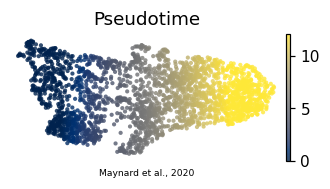

In [8]:
# sanitize non-serializable ElPiGraph uns entry (node positions kept; graph lives in uns['graph'])
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'%s' % 'Maynard et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')
plt.show()